Generazione matrice ricorrente (può richiedere qualche secondo)...
Avvio simulazione dinamica...
Simulazione terminata.


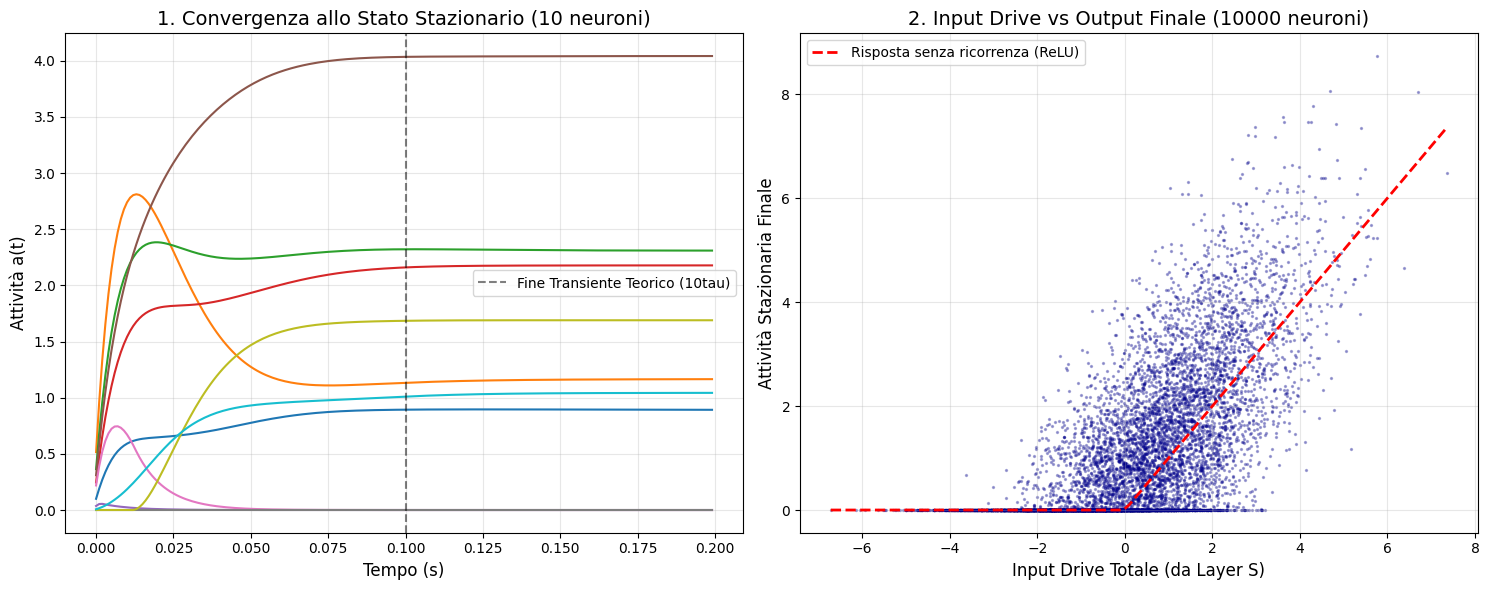

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PARAMETRI E SCALING (Regime Stazionario)
# ==========================================
N_S = 1000       # Input Layer
N_R = 10000      # Recurrent Layer (Grande)

tau = 0.01       # 10ms
dt = 0.001       # 1ms
steps = 200     # 2 secondi (più che sufficienti per convergere)

# --- CRUCIALE PER LA CONVERGENZA ---
# g_rec < 1.0 garantisce che la rete NON entri in caos.
# g_input alto assicura che la rete si accenda bene.
g_rec_factor = 0.9          # < 1.0 = STABILITÀ GARANTITA
g_input_factor = 2.5        # Input forte

# Scaling corretto per le dimensioni della rete
g_in = g_input_factor / np.sqrt(N_S)
g_rec = g_rec_factor / np.sqrt(N_R)

# Usa float32 per risparmiare RAM con matrici grandi
dtype = np.float32

# ==========================================
# 2. INIZIALIZZAZIONE MATRICI E INPUT
# ==========================================
print("Generazione matrice ricorrente (può richiedere qualche secondo)...")
# Matrice Recurrent (Sparsa o densa, qui densa ma stabile)
J_rec = (np.random.randn(N_R, N_R) * g_rec).astype(dtype)

# Matrice Input
J_in = (np.random.randn(N_R, N_S) * g_in).astype(dtype)

# Generazione Pattern Input (0/1)
pattern_S = np.random.choice([0, 1], size=N_S, p=[0.5, 0.5]).astype(dtype)

# Calcolo Input Drive (Statico)
# Questo è il termine "I_ext" che ogni neurone R riceve
I_drive = np.dot(J_in, pattern_S)

# ==========================================
# 3. EVOLUZIONE TEMPORALE
# ==========================================
a_R = np.zeros(N_R, dtype=dtype)

# Per il PLOT 1: Salviamo la storia solo di 10 neuroni (per non riempire la RAM)
idx_to_plot = np.random.choice(N_R, 10, replace=False)
history_sample = np.zeros((steps, 10))

print("Avvio simulazione dinamica...")

for t in range(steps):
    # Calcolo campi
    # H_tot = (J_rec * a) + I_drive
    total_field = np.dot(J_rec, a_R) + I_drive
    
    # Equazione differenziale: da/dt = (-a + ReLU(H))/tau
    d_a = (-a_R + np.maximum(0, total_field)) / tau
    
    # Update Eulero
    a_R += d_a * dt
    
    # Salviamo solo i neuroni scelti per il grafico
    history_sample[t, :] = a_R[idx_to_plot]

print("Simulazione terminata.")

# ==========================================
# 4. VISUALIZZAZIONE RISULTATI
# ==========================================
# Lo stato stazionario è semplicemente l'ultimo stato raggiunto
a_steady = a_R 

# Creiamo i due grafici richiesti
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# --- PLOT 1: Dinamica Temporale (deve essere piatta alla fine) ---
time_axis = np.arange(steps) * dt
ax1.plot(time_axis, history_sample, linewidth=1.5)
ax1.set_title("1. Convergenza allo Stato Stazionario (10 neuroni)", fontsize=14)
ax1.set_xlabel("Tempo (s)", fontsize=12)
ax1.set_ylabel("Attività a(t)", fontsize=12)
ax1.grid(True, alpha=0.3)
# Linea verticale per indicare la fine del transiente approssimativo (10*tau)
ax1.axvline(10*tau, color='k', linestyle='--', alpha=0.5, label='Fine Transiente Teorico (10tau)')
ax1.legend()

# --- PLOT 2: Input Drive vs Stato Stazionario ---
# Mostriamo tutti i 10.000 neuroni come punti
ax2.scatter(I_drive, a_steady, alpha=0.3, s=2, c='darkblue')

# Aggiungiamo una linea rossa che rappresenta la ReLU pura (y = max(0, x))
# Se J_rec fosse 0, tutti i punti cadrebbero su questa linea.
# La dispersione mostra l'effetto della rete ricorrente.
x_ref = np.linspace(min(I_drive), max(I_drive), 100)
y_ref = np.maximum(0, x_ref)
ax2.plot(x_ref, y_ref, 'r--', label='Risposta senza ricorrenza (ReLU)', linewidth=2)

ax2.set_title(f"2. Input Drive vs Output Finale ({N_R} neuroni)", fontsize=14)
ax2.set_xlabel("Input Drive Totale (da Layer S)", fontsize=12)
ax2.set_ylabel("Attività Stazionaria Finale", fontsize=12)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()